In [45]:
import pandas as pd
import os

In [46]:
df = pd.read_csv('dados-base/nasa_exoplanets_archive.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   pl_name                    6445 non-null   str    
 1   hostname                   6445 non-null   str    
 2   sy_snum                    6445 non-null   int64  
 3   sy_pnum                    6445 non-null   int64  
 4   discoverymethod            6445 non-null   str    
 5   disc_year                  6445 non-null   int64  
 6   disc_facility              6445 non-null   str    
 7   pl_orbper                  6078 non-null   float64
 8   pl_rade                    4822 non-null   float64
 9   pl_bmasse                  3184 non-null   float64
 10  pl_dens                    1264 non-null   float64
 11  pl_eqt                     1774 non-null   float64
 12  st_teff                    5675 non-null   float64
 13  st_rad                     5605 non-null   float64
 14  st_

In [47]:
df.head(6)

,pl_name,hostname,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,pl_orbper,pl_rade,pl_bmasse,...,st_met,sy_dist,sy_vmag,evidence_span,cot_rationale,planetary_archetype,thermal_habitability_zone,orbital_architecture_tier,stellar_host_class,confidence_score
0,CD-35 2722 B b,CD-35 2722 B,2,1,Radial Velocity,2026,Paranal Observatory,171.11000,NaN,292.402134,...,NaN,NaN,NaN,R: nan | M: 292.40 M_earth | P: 171.11d | Teq:...,Planet 'CD-35 2722 B b' orbiting 'CD-35 2722 B...,gas_giant_jupiter,conservative_habitable,habitable_zone_orbital,red_m_dwarf,0.95
1,DMPP-2 c,DMPP-2,1,3,Radial Velocity,2026,Multiple Observatories,3.16800,NaN,51.790000,...,NaN,137.9400,8.57,R: nan | M: 51.79 M_earth | P: 3.17d | Teq: 85...,Planet 'DMPP-2 c' orbiting 'DMPP-2' exhibits m...,gas_giant_jupiter,hot_inferno,inner_compact,hot_massive_f_a_type,0.92
2,DMPP-2 d,DMPP-2,1,3,Radial Velocity,2026,Multiple Observatories,16.49100,NaN,91.790000,...,NaN,137.9400,8.57,R: nan | M: 91.79 M_earth | P: 16.49d | Teq: 4...,Planet 'DMPP-2 d' orbiting 'DMPP-2' exhibits m...,gas_giant_jupiter,warm_temperate,habitable_zone_orbital,hot_massive_f_a_type,0.92
3,DMPP-6 b,DMPP-6,1,2,Radial Velocity,2026,Multiple Observatories,7.60270,NaN,5.800000,...,NaN,54.6303,7.71,R: nan | M: 5.80 M_earth | P: 7.60d | Teq: 850...,Planet 'DMPP-6 b' orbiting 'DMPP-6' exhibits m...,super_earth,hot_inferno,inner_compact,solar_analog_g_dwarf,0.95
4,DMPP-6 c,DMPP-6,1,2,Radial Velocity,2026,Multiple Observatories,36.44100,NaN,13.470000,...,NaN,54.6303,7.71,R: nan | M: 13.47 M_earth | P: 36.44d | Teq: 4...,Planet 'DMPP-6 c' orbiting 'DMPP-6' exhibits m...,sub_neptune_mini_gas,warm_temperate,habitable_zone_orbital,solar_analog_g_dwarf,0.95
5,DMPP-7 b,DMPP-7,1,1,Radial Velocity,2026,Multiple Observatories,4.92666,NaN,68.958000,...,0.13,101.3860,8.79,R: nan | M: 68.96 M_earth | P: 4.93d | Teq: 14...,Planet 'DMPP-7 b' orbiting 'DMPP-7' exhibits m...,gas_giant_jupiter,hot_inferno,inner_compact,hot_massive_f_a_type,0.92


In [48]:
print(df['disc_facility'].nunique())
df['disc_facility'].unique()

73


<StringArray>
[                                         'Paranal Observatory',
                                       'Multiple Observatories',
                                         'La Silla Observatory',
                                          'Multiple Facilities',
                                        'Mauna Kea Observatory',
                   'European Space Agency (ESA) Gaia Satellite',
                 'Transiting Exoplanet Survey Satellite (TESS)',
                                     'Las Campanas Observatory',
                           'Roque de los Muchachos Observatory',
                                             'Subaru Telescope',
                                                       'KMTNet',
                                       'W. M. Keck Observatory',
                 'CHaracterising ExOPlanets Satellite (CHEOPS)',
                                                          'MOA',
                                                         'OGLE',
           

In [49]:
n=6441


In [50]:
df['evidence_span'][n]

'R: nan | M: 193.88 M_earth | P: 4.23d | Teq: 1211K | Star: T_eff=5761K (5200-6000K)'

In [51]:
print(df['pl_rade'][n])
print(df['pl_bmasse'][n])
print(df['pl_orbper'][n])
print(df['pl_eqt'][n])
print(df['st_teff'][n])
print(df['thermal_habitability_zone'][n])
print(df['orbital_architecture_tier'][n])

nan
193.87532827
4.2307966
nan
5761.0
hot_inferno
inner_compact


In [52]:
df['cot_rationale'][n]

"Planet '51 Peg b' orbiting '51 Peg' exhibits mass 193.88 M_earth (50.0-4000.0), classifying as 'gas_giant_jupiter'. With equilibrium temperature calculated T_eq 1211K, it falls into the 'hot_inferno' regime. Orbital architecture shows P=4.23d (1-10d), denoting 'inner_compact'. Host star temperature indicates 'solar_analog_g_dwarf' (T_eff=5761K (5200-6000K))."

In [53]:
print(df['planetary_archetype'][n])
print(df['thermal_habitability_zone'][n])
print(df['orbital_architecture_tier'][n])
print(df['stellar_host_class'][n])

gas_giant_jupiter
hot_inferno
inner_compact
solar_analog_g_dwarf


In [54]:
resumo = pd.DataFrame({
    "non-null": df.notna().sum(),
    "NaN": df.isna().sum()
})

resumo["soma"] = resumo["non-null"] + resumo["NaN"]

print(resumo)

                           non-null   NaN  soma
pl_name                        6445     0  6445
hostname                       6445     0  6445
sy_snum                        6445     0  6445
sy_pnum                        6445     0  6445
discoverymethod                6445     0  6445
disc_year                      6445     0  6445
disc_facility                  6445     0  6445
pl_orbper                      6078   367  6445
pl_rade                        4822  1623  6445
pl_bmasse                      3184  3261  6445
pl_dens                        1264  5181  6445
pl_eqt                         1774  4671  6445
st_teff                        5675   770  6445
st_rad                         5605   840  6445
st_mass                        5568   877  6445
st_met                         4437  2008  6445
sy_dist                        6317   128  6445
sy_vmag                        6124   321  6445
evidence_span                  6445     0  6445
cot_rationale                  6445     

In [55]:
df_original = df.copy()

In [56]:
df['discoverymethod'].unique()

<StringArray>
[              'Radial Velocity',                  'Microlensing',
                       'Transit',                       'Imaging',
     'Transit Timing Variations',                    'Astrometry',
                 'Pulsar Timing',     'Eclipse Timing Variations',
 'Orbital Brightness Modulation',               'Disk Kinematics',
   'Pulsation Timing Variations']
Length: 11, dtype: str

In [57]:
df['planetary_archetype'].unique()

<StringArray>
[    'gas_giant_jupiter',           'super_earth',  'sub_neptune_mini_gas',
     'terrestrial_rocky', 'super_jupiter_extreme']
Length: 5, dtype: str

In [58]:
df['thermal_habitability_zone'].unique()

<StringArray>
['conservative_habitable', 'hot_inferno', 'warm_temperate',
 'cryogenic_frigid']
Length: 4, dtype: str

In [59]:
df['orbital_architecture_tier'].unique()

<StringArray>
['habitable_zone_orbital',          'inner_compact',      'outer_cold_system',
     'ultra_short_period']
Length: 4, dtype: str

In [60]:
df['stellar_host_class'].unique()

<StringArray>
['red_m_dwarf', 'hot_massive_f_a_type', 'solar_analog_g_dwarf',
 'orange_k_dwarf']
Length: 4, dtype: str

In [61]:
traducoes = {
    "discoverymethod": {
        "Transit Timing Variations": "Variações no Tempo de Trânsito (TTV)",
        "Astrometry": "Astrometria",
        "Pulsar Timing": "Cronometragem de Pulsar" ,
        "Eclipse Timing Variations": "Variações no Tempo de Eclipse" ,
        "Orbital Brightness Modulation": "Modulação de Brilho Orbital" ,
        "Disk Kinematics": "Cinemática de Disco" ,
        "Pulsation Timing Variations": "Variações no Tempo de Pulsacao" ,
        "Transit": "Trânsito",
        "Radial Velocity": "Velocidade Radial",
        "Microlensing": "Microlente Gravitacional",
        "Imaging": "Imagem Direta "
    },
    "disc_facility": {
        "Paranal Observatory": "Observatório Paranal",
        "Multiple Observatories": "Múltiplos Observatórios",
        "La Silla Observatory": "Observatório de La Silla",
        "Multiple Facilities": "Múltiplas Instalações",
        "Mauna Kea Observatory": "Observatório de Mauna Kea",
        "European Space Agency (ESA) Gaia Satellite": "Satélite Gaia da Agência Espacial Europeia (ESA)",
        "Transiting Exoplanet Survey Satellite (TESS)": "Satélite de Pesquisa de Exoplanetas em Trânsito (TESS)",
        "Las Campanas Observatory": "Observatório Las Campanas",
        "Roque de los Muchachos Observatory": "Observatório Roque de los Muchachos",
        "Subaru Telescope": "Telescópio Subaru",
        "KMTNet": "KMTNet",
        "W. M. Keck Observatory": "Observatório W. M. Keck",
        "CHaracterising ExOPlanets Satellite (CHEOPS)": "Satélite de Caracterização de Exoplanetas (CHEOPS)",
        "MOA": "MOA",
        "OGLE": "OGLE",
        "Kepler": "Kepler",
        "K2": "K2",
        "Haute-Provence Observatory": "Observatório de Haute-Provence",
        "Gemini Observatory": "Observatório Gemini",
        "James Webb Space Telescope (JWST)": "Telescópio Espacial James Webb (JWST)",
        "Calar Alto Observatory": "Observatório de Calar Alto",
        "Next-Generation Transit Survey (NGTS)": "Pesquisa de Trânsito de Nova Geração (NGTS)",
        "SuperWASP": "SuperWASP",
        "Zwicky Transient Facility": "Instalação de Transientes Zwicky",
        "McDonald Observatory": "Observatório McDonald",
        "South African Radio Astronomy Observatory (SARAO)": "Observatório de Radioastronomia da África do Sul (SARAO)",
        "SPECULOOS Southern Observatory": "Observatório do Sul SPECULOOS",
        "Lick Observatory": "Observatório Lick",
        "Okayama Astrophysical Observatory": "Observatório Astrofísico de Okayama",
        "Bohyunsan Optical Astronomical Observatory": "Observatório Astronômico Óptico de Bohyunsan",
        "Spitzer Space Telescope": "Telescópio Espacial Spitzer",
        "Large Binocular Telescope Observatory": "Observatório do Grande Telescópio Binocular",
        "WASP-South": "WASP-South",
        "Lowell Observatory": "Observatório Lowell",
        "CoRoT": "CoRoT",
        "Very Long Baseline Array": "Matriz de Linha de Base Muito Longa (VLBA)",
        "European Southern Observatory": "Observatório Europeu do Sul (ESO)",
        "Wide-field Infrared Survey Explorer (WISE) Satellite Mission": "Missão do Satélite Explorador de Pesquisa em Infravermelho de Campo Amplo (WISE)",
        "NASA Infrared Telescope Facility (IRTF)": "Instalação do Telescópio Infravermelho da NASA (IRTF)",
        "Acton Sky Portal Observatory": "Observatório Acton Sky Portal",
        "HATNet": "HATNet",
        "HATSouth": "HATSouth",
        "Cerro Tololo Inter-American Observatory": "Observatório Interamericano de Cerro Tololo",
        "Hubble Space Telescope": "Telescópio Espacial Hubble",
        "SuperWASP-North": "SuperWASP-North",
        "Haleakala Observatory": "Observatório de Haleakala",
        "Anglo-Australian Telescope": "Telescópio Anglo-Australiano",
        "Atacama Large Millimeter Array (ALMA)": "Grande Arranjo Milimétrico do Atacama (ALMA)",
        "KELT-North": "KELT-North",
        "KOINet": "KOINet",
        "Winer Observatory": "Observatório Winer",
        "Qatar": "Catar",
        "XO": "XO",
        "The 2 (Two) Micron All Sky Survey (2MASS)": "Pesquisa de Todo o Céu em 2 Mícrons (2MASS)",
        "SuperWASP-South": "SuperWASP-South",
        "KELT-South": "KELT-South",
        "KELT": "KELT",
        "MEarth Project": "Projeto MEarth",
        "Parkes Observatory": "Observatório de Parkes",
        "Apache Point Observatory": "Observatório de Apache Point",
        "University of Canterbury Mt John Observatory": "Observatório de Mt John da Universidade de Canterbury",
        "Fred Lawrence Whipple Observatory": "Observatório Fred Lawrence Whipple",
        "United Kingdom Infrared Telescope": "Telescópio Infravermelho do Reino Unido",
        "Leoncito Astronomical Complex": "Complexo Astronômico El Leoncito",
        "Yunnan Astronomical Observatory": "Observatório Astronômico de Yunnan",
        "TrES": "TrES",
        "Palomar Observatory": "Observatório Palomar",
        "Infrared Survey Facility": "Instalação de Pesquisa em Infravermelho",
        "Thueringer Landessternwarte Tautenburg": "Observatório Estadual da Turíngia Tautenburg",
        "Xinglong Station": "Estação de Xinglong",
        "Teide Observatory": "Observatório de Teide",
        "Kitt Peak National Observatory": "Observatório Nacional de Kitt Peak",
        "Arecibo Observatory": "Observatório de Arecibo"
    },
    "planetary_archetype": {
        "sub_neptune_mini_gas": "Sub-Netuno/Mini gasoso",
        "gas_giant_jupiter": "Gigante gasoso/Júpiter",
        "super_earth": "Superterra",
        "terrestrial_rocky": "Terrestre Rochoso",
        "super_jupiter_extreme": "Super-Júpiter Extremo"
    },
    "thermal_habitability_zone": {
        "conservative_habitable": "Zona Habitável Conservadora",
        "hot_inferno": "Infernal",
        "warm_temperate": "Morno/Temperado",
        "cryogenic_frigid": "Gélido/Criogênico"
    },
    "orbital_architecture_tier": {
        "habitable_zone_orbital": "Órbita na Zona Habitável",
        "inner_compact": "Sistema Interno Compacto",
        "outer_cold_system": "Sistema Externo Frio",
        "ultra_short_period": "Período Ultracurto"
    },
    "stellar_host_class": {
        "red_m_dwarf": "Anã Vermelha (Classe M)",
        "hot_massive_f_a_type": "Estrela Massiva Quente (Classes F/A)",
        "solar_analog_g_dwarf": "Análoga ao Sol (Anã Classe G)",
        "orange_k_dwarf": "Anã Laranja (Classe K)"
    }
}

for coluna, mapa in traducoes.items():
    df[coluna] = df[coluna].replace(mapa)

In [62]:
traducao_colunas = {
    "pl_name": "nome_planeta",
    "hostname": "nome_estrela_primaria",
    "sy_snum": "num_estrelas_sistema",
    "sy_pnum": "num_planetas_sistema",
    "discoverymethod": "metodo_descoberta",
    "disc_year": "ano_descoberta",
    "disc_facility": "observatorio_descoberta",
    "pl_orbper": "periodo_orbital", ## Em dias terrestres
    "pl_rade": "raio_planetario", ## Em termos de Terras
    "pl_bmasse": "massa_planetaria", ## Em termos de Terras
    "pl_dens": "densidade_planetaria", ## Em g/cm³
    "pl_eqt": "temp_equilibrio_superf_planetaria", ## Em Kelvin
    "st_teff": "temp_superf_estelar", ## Em Kelvin
    "st_rad": "raio_estelar", ## Em raios solares
    "st_mass": "massa_estelar", ## Em massas solares
    "st_met": "metalicidade_estelar", # [Fe/H] em dex
    "sy_dist": "distancia_sistema", # Do sistema solar à estrela, em parsecs
    "sy_vmag": "magnitude_visual_estrela",
    "evidence_span": "trecho_evidencia",
    "cot_rationale": "raciocinio_cot",
    "planetary_archetype": "arquetipo_planetario",
    "thermal_habitability_zone": "zona_habitabilidade_termica",
    "orbital_architecture_tier": "nivel_arquitetura_orbital",
    "stellar_host_class": "classe_estelar",
    "confidence_score": "pontuacao_confianca"
}

df = df.rename(columns=traducao_colunas)

In [63]:
df_traduzido = df.copy()

In [64]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   pl_name                    6445 non-null   str    
 1   hostname                   6445 non-null   str    
 2   sy_snum                    6445 non-null   int64  
 3   sy_pnum                    6445 non-null   int64  
 4   discoverymethod            6445 non-null   str    
 5   disc_year                  6445 non-null   int64  
 6   disc_facility              6445 non-null   str    
 7   pl_orbper                  6078 non-null   float64
 8   pl_rade                    4822 non-null   float64
 9   pl_bmasse                  3184 non-null   float64
 10  pl_dens                    1264 non-null   float64
 11  pl_eqt                     1774 non-null   float64
 12  st_teff                    5675 non-null   float64
 13  st_rad                     5605 non-null   float64
 14  st_

In [65]:
df_traduzido.info()

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   nome_planeta                       6445 non-null   str    
 1   nome_estrela_primaria              6445 non-null   str    
 2   num_estrelas_sistema               6445 non-null   int64  
 3   num_planetas_sistema               6445 non-null   int64  
 4   metodo_descoberta                  6445 non-null   str    
 5   ano_descoberta                     6445 non-null   int64  
 6   observatorio_descoberta            6445 non-null   str    
 7   periodo_orbital                    6078 non-null   float64
 8   raio_planetario                    4822 non-null   float64
 9   massa_planetaria                   3184 non-null   float64
 10  densidade_planetaria               1264 non-null   float64
 11  temp_equilibrio_superf_planetaria  1774 non-null   float64
 12  tem

In [66]:
df_traduzido['metodo_descoberta'].unique()

<StringArray>
[                   'Velocidade Radial',
             'Microlente Gravitacional',
                             'Trânsito',
                       'Imagem Direta ',
 'Variações no Tempo de Trânsito (TTV)',
                          'Astrometria',
              'Cronometragem de Pulsar',
        'Variações no Tempo de Eclipse',
          'Modulação de Brilho Orbital',
                  'Cinemática de Disco',
       'Variações no Tempo de Pulsacao']
Length: 11, dtype: str

In [67]:
df['arquetipo_planetario'].unique()

<StringArray>
['Gigante gasoso/Júpiter',             'Superterra', 'Sub-Netuno/Mini gasoso',
      'Terrestre Rochoso',  'Super-Júpiter Extremo']
Length: 5, dtype: str

In [68]:
df['zona_habitabilidade_termica'].unique()

<StringArray>
['Zona Habitável Conservadora',                    'Infernal',
             'Morno/Temperado',           'Gélido/Criogênico']
Length: 4, dtype: str

In [69]:
df['nivel_arquitetura_orbital'].unique()

<StringArray>
['Órbita na Zona Habitável', 'Sistema Interno Compacto',
     'Sistema Externo Frio',       'Período Ultracurto']
Length: 4, dtype: str

In [70]:
df['classe_estelar'].unique()

<StringArray>
[             'Anã Vermelha (Classe M)',
 'Estrela Massiva Quente (Classes F/A)',
        'Análoga ao Sol (Anã Classe G)',
               'Anã Laranja (Classe K)']
Length: 4, dtype: str

In [71]:
resumo2 = pd.DataFrame({
    "non-null": df_traduzido.notna().sum(),
    "NaN": df_traduzido.isna().sum()
})

resumo2["soma"] = resumo2["non-null"] + resumo2["NaN"]

print(resumo)
print(resumo2)

                           non-null   NaN  soma
pl_name                        6445     0  6445
hostname                       6445     0  6445
sy_snum                        6445     0  6445
sy_pnum                        6445     0  6445
discoverymethod                6445     0  6445
disc_year                      6445     0  6445
disc_facility                  6445     0  6445
pl_orbper                      6078   367  6445
pl_rade                        4822  1623  6445
pl_bmasse                      3184  3261  6445
pl_dens                        1264  5181  6445
pl_eqt                         1774  4671  6445
st_teff                        5675   770  6445
st_rad                         5605   840  6445
st_mass                        5568   877  6445
st_met                         4437  2008  6445
sy_dist                        6317   128  6445
sy_vmag                        6124   321  6445
evidence_span                  6445     0  6445
cot_rationale                  6445     

In [72]:
df.to_csv('dados-base/exoplanetas_traduzidos.csv', index=False, encoding='utf-8')

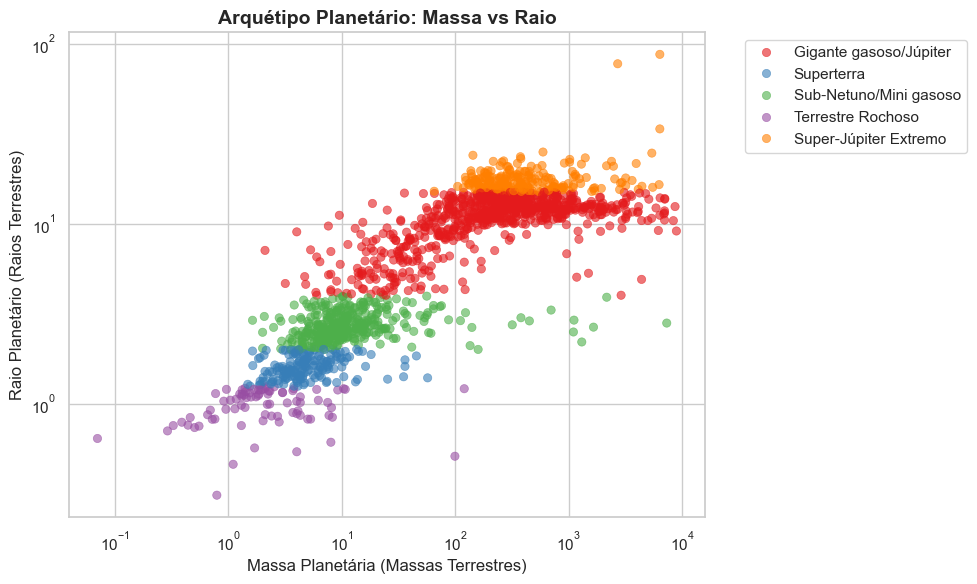

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Gráfico de dispersão dos arquétipos planetários (Massa x Raio)
plt.figure(figsize=(10, 6))
df_plot1 = df_traduzido.dropna(subset=['massa_planetaria', 'raio_planetario', 'arquetipo_planetario'])

sns.scatterplot(
    data=df_plot1,
    x='massa_planetaria',
    y='raio_planetario',
    hue='arquetipo_planetario',
    palette='Set1',
    alpha=0.6,
    edgecolor=None
)
plt.title('Arquétipo Planetário: Massa vs Raio', fontsize=14, weight='bold')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Massa Planetária (Massas Terrestres)')
plt.ylabel('Raio Planetário (Raios Terrestres)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.savefig('graficos/01_massa_vs_raio.png', dpi=300, bbox_inches='tight')
plt.show()

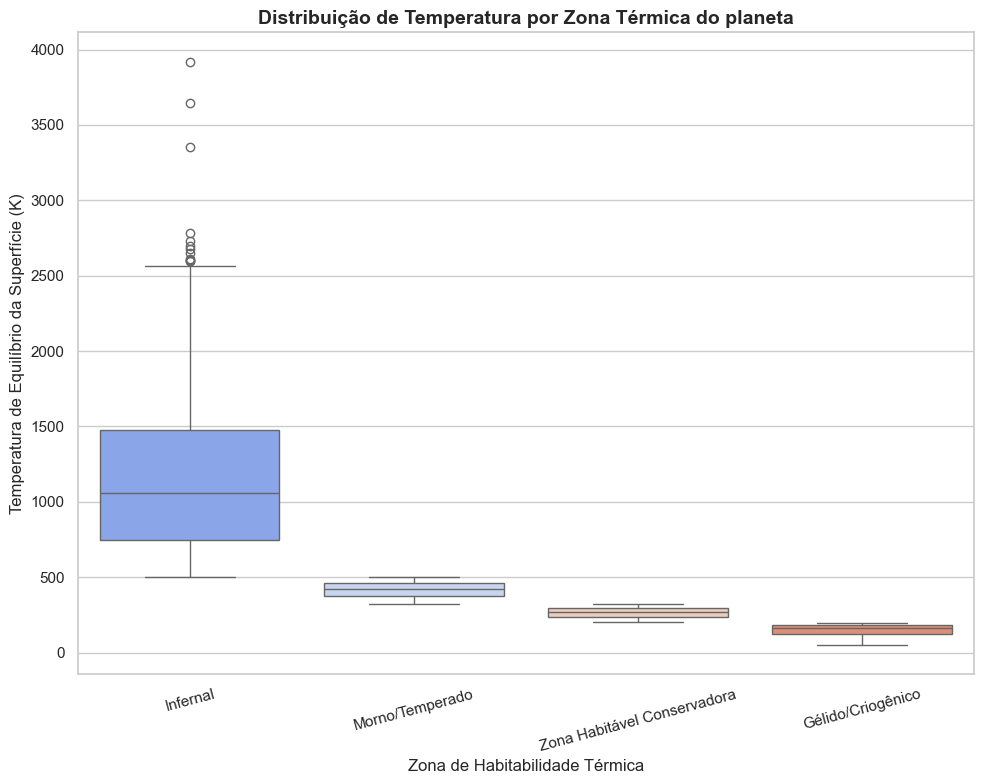

In [74]:
# Zona de habitabilidade e temperatura da superfície
plt.figure(figsize=(10, 8))
df_plot2a = df_traduzido.dropna(subset=['zona_habitabilidade_termica', 'temp_equilibrio_superf_planetaria'])

sns.boxplot(
    data=df_plot2a,
    x='zona_habitabilidade_termica',
    y='temp_equilibrio_superf_planetaria',
    hue='zona_habitabilidade_termica',
    palette='coolwarm',
    legend=False
)
plt.title('Distribuição de Temperatura por Zona Térmica do planeta', fontsize=14, weight='bold')
plt.ylabel('Temperatura de Equilíbrio da Superfície (K)')
plt.xlabel('Zona de Habitabilidade Térmica')
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig('graficos/02_zona_termica_temperatura.png', dpi=300, bbox_inches='tight')
plt.show()

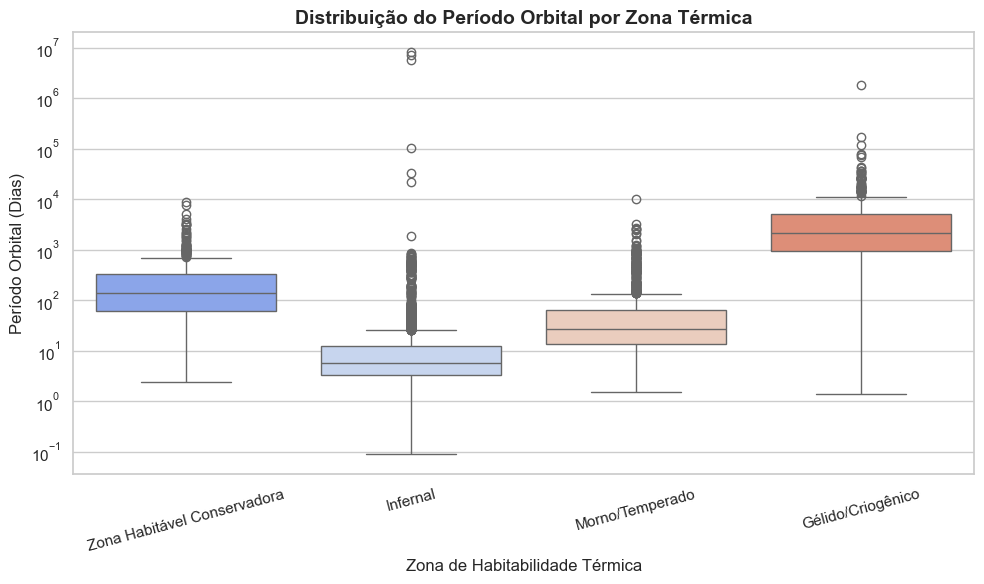

In [75]:
# Zona de habitabilidade e período orbital
plt.figure(figsize=(10, 6))
df_plot2b = df_traduzido.dropna(subset=['zona_habitabilidade_termica', 'periodo_orbital'])

sns.boxplot(
    data=df_plot2b,
    x='zona_habitabilidade_termica',
    y='periodo_orbital',
    hue='zona_habitabilidade_termica',
    palette='coolwarm',
    legend=False
)

plt.title('Distribuição do Período Orbital por Zona Térmica', fontsize=14, weight='bold')
plt.yscale('log')
plt.ylabel('Período Orbital (Dias)')
plt.xlabel('Zona de Habitabilidade Térmica')
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig('graficos/03_zona_termica_periodo.png', dpi=300, bbox_inches='tight')
plt.show()

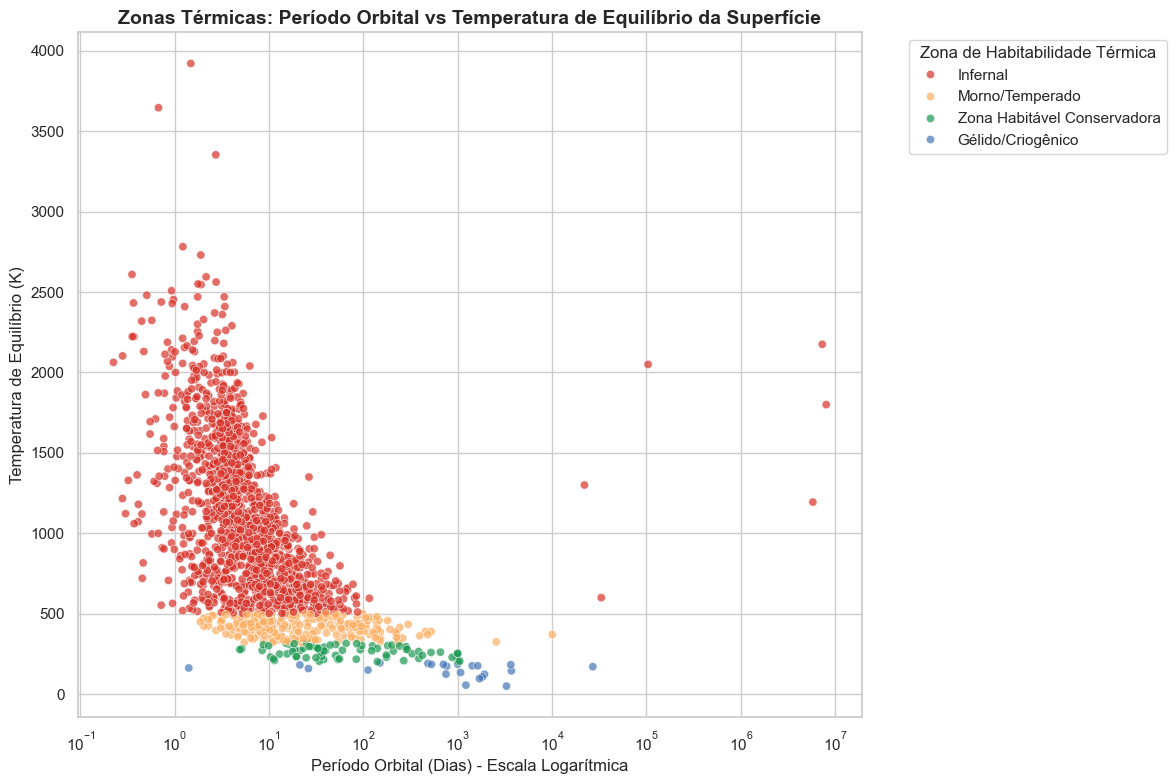

In [76]:
# Gráfico de dispersão das Zonas de Habitabilidade Térmica (Período Orbital x Temperatura de Equilíbrio da Superfície)
df_plot_termica = df_traduzido.dropna(subset=[
    'periodo_orbital',
    'temp_equilibrio_superf_planetaria',
    'zona_habitabilidade_termica'
])

plt.figure(figsize=(12, 8))

cores_zonas = {
    'Infernal': '#d73027',                     # Vermelho
    'Morno/Temperado': '#fdae61',              # Laranja
    'Zona Habitável Conservadora': '#1a9850',  # Verde
    'Gélido/Criogênico': '#4575b4'             # Azul
}

sns.scatterplot(
    data=df_plot_termica,
    x='periodo_orbital',
    y='temp_equilibrio_superf_planetaria',
    hue='zona_habitabilidade_termica',
    palette=cores_zonas,
    alpha=0.7,
    edgecolor='w',
    linewidth=0.5
)

plt.title('Zonas Térmicas: Período Orbital vs Temperatura de Equilíbrio da Superfície', fontsize=14, weight='bold')
plt.xlabel('Período Orbital (Dias) - Escala Logarítmica')
plt.ylabel('Temperatura de Equilíbrio (K)')

plt.xscale('log')

plt.legend(title='Zona de Habitabilidade Térmica', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

plt.savefig('graficos/04_periodo_vs_temperatura.png', dpi=300, bbox_inches='tight')
plt.show()

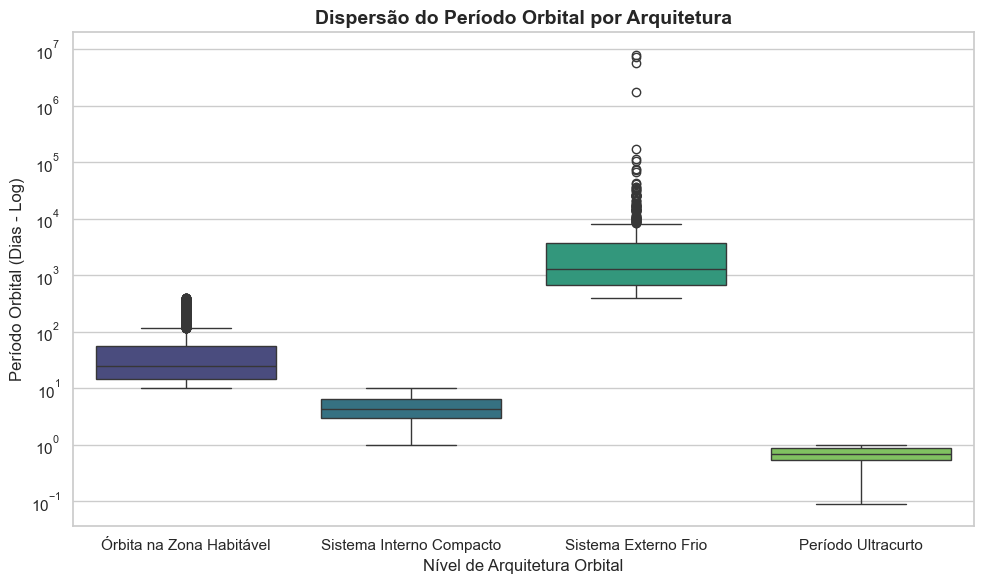

In [77]:
# Arquitetura orbital e período orbital
plt.figure(figsize=(10, 6))
df_plot3 = df_traduzido.dropna(subset=['nivel_arquitetura_orbital', 'periodo_orbital'])

sns.boxplot(
    data=df_plot3,
    x='nivel_arquitetura_orbital',
    y='periodo_orbital',
    hue='nivel_arquitetura_orbital',
    palette='viridis',
    legend=False
)
plt.title('Dispersão do Período Orbital por Arquitetura', fontsize=14, weight='bold')
plt.yscale('log')
plt.xlabel('Nível de Arquitetura Orbital')
plt.ylabel('Período Orbital (Dias - Log)')
plt.tight_layout()

plt.savefig('graficos/05_arquitetura_orbital.png', dpi=300, bbox_inches='tight')
plt.show()

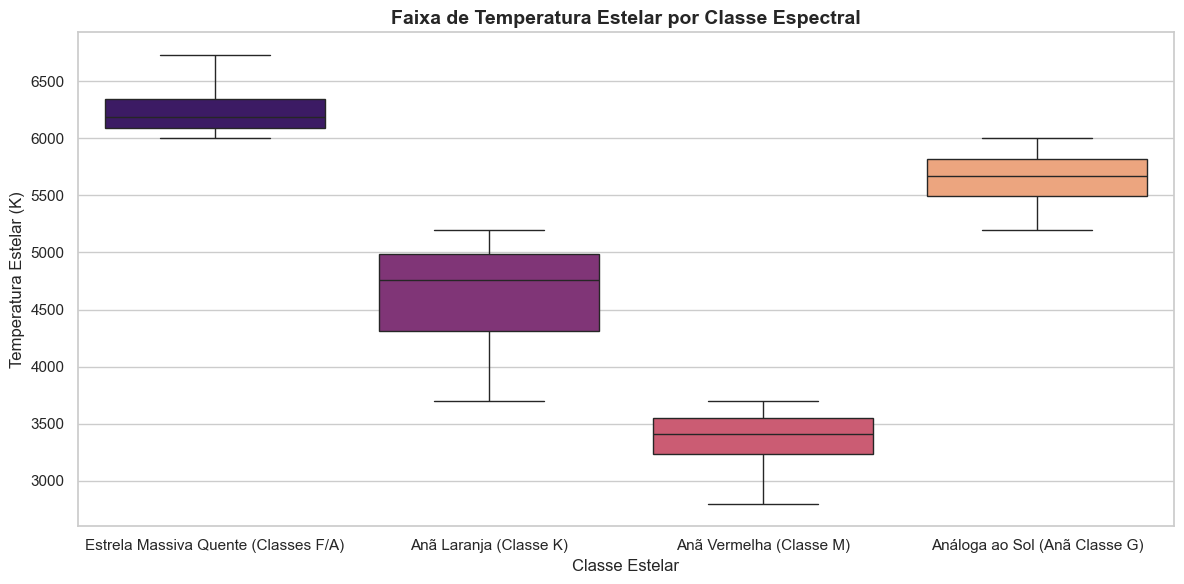

In [78]:
# Classe Estelar vs Temperatura
plt.figure(figsize=(12, 6))
df_plot4 = df_traduzido.dropna(subset=['classe_estelar', 'temp_superf_estelar'])

sns.boxplot(
    data=df_plot4,
    x='classe_estelar',
    y='temp_superf_estelar',
    hue='classe_estelar',
    palette='magma',
    legend=False,
    showfliers=False
)
plt.title('Faixa de Temperatura Estelar por Classe Espectral', fontsize=14, weight='bold')
plt.xlabel('Classe Estelar')
plt.ylabel('Temperatura Estelar (K)')
plt.tight_layout()

plt.savefig('graficos/06_classe_estelar.png', dpi=300, bbox_inches='tight')
plt.show()

In [79]:
df_traduzido.info()

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   nome_planeta                       6445 non-null   str    
 1   nome_estrela_primaria              6445 non-null   str    
 2   num_estrelas_sistema               6445 non-null   int64  
 3   num_planetas_sistema               6445 non-null   int64  
 4   metodo_descoberta                  6445 non-null   str    
 5   ano_descoberta                     6445 non-null   int64  
 6   observatorio_descoberta            6445 non-null   str    
 7   periodo_orbital                    6078 non-null   float64
 8   raio_planetario                    4822 non-null   float64
 9   massa_planetaria                   3184 non-null   float64
 10  densidade_planetaria               1264 non-null   float64
 11  temp_equilibrio_superf_planetaria  1774 non-null   float64
 12  tem

In [118]:
df_traduzido2 = df_traduzido.copy()

In [119]:
df_traduzido2['metodo_descoberta'].value_counts()

metodo_descoberta
Trânsito                                4781
Velocidade Radial                       1203
Microlente Gravitacional                 292
Imagem Direta                             97
Variações no Tempo de Trânsito (TTV)      29
Variações no Tempo de Eclipse             17
Modulação de Brilho Orbital                9
Cronometragem de Pulsar                    8
Astrometria                                6
Variações no Tempo de Pulsacao             2
Cinemática de Disco                        1
Name: count, dtype: int64

In [121]:
contagem = df_traduzido2['metodo_descoberta'].value_counts()

outros = contagem[contagem < 100].index

df_traduzido2['metodo_descoberta'] = df_traduzido2['metodo_descoberta'].replace(outros, 'Outros')

df_traduzido2['metodo_descoberta'].value_counts()

metodo_descoberta
Trânsito                    4781
Velocidade Radial           1203
Microlente Gravitacional     292
Outros                       169
Name: count, dtype: int64

In [122]:
df_traduzido2['observatorio_descoberta'].value_counts()

observatorio_descoberta
Kepler                                                    2787
Satélite de Pesquisa de Exoplanetas em Trânsito (TESS)    1008
K2                                                         550
Múltiplos Observatórios                                    355
Observatório de La Silla                                   311
                                                          ... 
Observatório de Mt John da Universidade de Canterbury        1
Complexo Astronômico El Leoncito                             1
Instalação de Pesquisa em Infravermelho                      1
Observatório de Teide                                        1
Observatório Nacional de Kitt Peak                           1
Name: count, Length: 73, dtype: int64

In [123]:
contagem = df_traduzido2['observatorio_descoberta'].value_counts()

outros = contagem[contagem < 50].index

df_traduzido2['observatorio_descoberta'] = df_traduzido2['observatorio_descoberta'].replace(outros, 'Outros')

df_traduzido2['observatorio_descoberta'].value_counts()

observatorio_descoberta
Kepler                                                    2787
Satélite de Pesquisa de Exoplanetas em Trânsito (TESS)    1008
Outros                                                     651
K2                                                         550
Múltiplos Observatórios                                    355
Observatório de La Silla                                   311
Observatório W. M. Keck                                    193
KMTNet                                                     147
SuperWASP                                                  122
OGLE                                                       112
HATSouth                                                    73
Observatório de Haute-Provence                              69
HATNet                                                      67
Name: count, dtype: int64

In [159]:
df_traduzido3 = df_traduzido2.copy()

In [160]:
df_traduzido3['ano_descoberta'].value_counts()

ano_descoberta
2016    1504
2014     872
2021     564
2022     367
2026     355
2023     323
2018     308
2024     260
2025     246
2020     234
2019     194
2015     155
2017     152
2012     144
2011     141
2013     128
2010      93
2009      87
2008      62
2007      52
2005      36
2006      32
2002      29
2004      27
2003      22
2000      16
1999      13
2001      12
1998       6
1996       6
1992       2
1997       1
1995       1
1994       1
Name: count, dtype: int64

In [161]:
agrupa = df_traduzido3['ano_descoberta'].value_counts()

a2020 = agrupa[agrupa.index >= 2020].index
a2010 = agrupa[(agrupa.index >= 2010) & (agrupa.index <= 2019)].index
a2000 = agrupa[(agrupa.index >= 2000) & (agrupa.index <= 2009)].index
a1990 = agrupa[(agrupa.index >= 1990) & (agrupa.index <= 1999)].index

df_traduzido3['ano_descoberta_disc'] = df_traduzido3['ano_descoberta']

df_traduzido3['ano_descoberta_disc'] = df_traduzido3['ano_descoberta_disc'].replace(a2020, '2020 - 2026')
df_traduzido3['ano_descoberta_disc'] = df_traduzido3['ano_descoberta_disc'].replace(a2010, '2010 - 2019')
df_traduzido3['ano_descoberta_disc'] = df_traduzido3['ano_descoberta_disc'].replace(a2000, '2000 - 2009')
df_traduzido3['ano_descoberta_disc'] = df_traduzido3['ano_descoberta_disc'].replace(a1990, '1990 - 1999')

df_traduzido3['ano_descoberta_disc'].value_counts()

ano_descoberta_disc
2010 - 2019    3691
2020 - 2026    2349
2000 - 2009     375
1990 - 1999      30
Name: count, dtype: int64

In [162]:
df_traduzido3['raio_planetario'].value_counts()

raio_planetario
2.600000     22
2.000000     22
1.330000     21
1.640000     21
1.320000     20
             ..
14.011000     1
11.421971     1
12.251000     1
15.278000     1
15.580510     1
Name: count, Length: 2171, dtype: int64

In [163]:
agrupa_raio = df_traduzido3['raio_planetario'].value_counts()

terrestre = agrupa_raio[agrupa_raio.index < 1.25].index
superterra = agrupa_raio[(agrupa_raio.index >= 1.25) & (agrupa_raio.index < 2)].index
subnetuno = agrupa_raio[(agrupa_raio.index >= 2) & (agrupa_raio.index < 4)].index
gigante = agrupa_raio[(agrupa_raio.index >= 4) & (agrupa_raio.index <= 15)].index
super_jupiter = agrupa_raio[agrupa_raio.index > 15].index

df_traduzido3['raio_planetario_disc'] = df_traduzido3['raio_planetario']

df_traduzido3['raio_planetario_disc'] = df_traduzido3['raio_planetario_disc'].replace(terrestre, 'Terrestre Rochoso (menos de 1,25 raio terrestre)')
df_traduzido3['raio_planetario_disc'] = df_traduzido3['raio_planetario_disc'].replace(superterra, 'Superterra (1,25 a 2 raios terrestres)')
df_traduzido3['raio_planetario_disc'] = df_traduzido3['raio_planetario_disc'].replace(subnetuno, 'Sub-Netuno/Mini gasoso (2 a 4 raios terrestres)')
df_traduzido3['raio_planetario_disc'] = df_traduzido3['raio_planetario_disc'].replace(gigante, 'Gigante gasoso/Júpiter (4 a 15 raios terrestres)')
df_traduzido3['raio_planetario_disc'] = df_traduzido3['raio_planetario_disc'].replace(super_jupiter, 'Super-Júpiter Extremo (mais que 15 raios terrestres)')

df_traduzido3['raio_planetario_disc'].value_counts()

raio_planetario_disc
Sub-Netuno/Mini gasoso (2 a 4 raios terrestres)         1893
Superterra (1,25 a 2 raios terrestres)                  1143
Gigante gasoso/Júpiter (4 a 15 raios terrestres)        1009
Terrestre Rochoso (menos de 1,25 raio terrestre)         542
Super-Júpiter Extremo (mais que 15 raios terrestres)     235
Name: count, dtype: int64

In [164]:
df_traduzido3['massa_planetaria'].value_counts()

massa_planetaria
8.000000       10
6674.396547     9
4.000000        8
6.200000        7
6.400000        7
               ..
804.080000      1
276.000000      1
2357.027280     1
218.531000      1
0.020000        1
Name: count, Length: 2330, dtype: int64

In [165]:
agrupa_massa = df_traduzido3['massa_planetaria'].value_counts()

terrestre_massa = agrupa_massa[agrupa_massa.index < 2].index
superterra_massa = agrupa_massa[(agrupa_massa.index >= 2) & (agrupa_massa.index < 10)].index
subnetuno_massa = agrupa_massa[(agrupa_massa.index >= 10) & (agrupa_massa.index < 50)].index
gigante_massa = agrupa_massa[(agrupa_massa.index >= 50) & (agrupa_massa.index <= 300)].index
super_jupiter_massa = agrupa_massa[agrupa_massa.index > 300].index

df_traduzido3['massa_planetaria_disc'] = df_traduzido3['massa_planetaria']

df_traduzido3['massa_planetaria_disc'] = df_traduzido3['massa_planetaria_disc'].replace(terrestre_massa, 'Terrestre/Sub-Terra (menos de 2 massas terrestres)')
df_traduzido3['massa_planetaria_disc'] = df_traduzido3['massa_planetaria_disc'].replace(superterra_massa, 'Superterra (2 a 10 massas terrestres)')
df_traduzido3['massa_planetaria_disc'] = df_traduzido3['massa_planetaria_disc'].replace(subnetuno_massa, 'Sub-Netuno/Mini gasoso (10 a 50 massas terrestres)')
df_traduzido3['massa_planetaria_disc'] = df_traduzido3['massa_planetaria_disc'].replace(gigante_massa, 'Gigante gasoso/Saturno-Júpiter (50 a 300 massas terrestres)')
df_traduzido3['massa_planetaria_disc'] = df_traduzido3['massa_planetaria_disc'].replace(super_jupiter_massa, 'Super-Júpiter (mais que 300 massas terrestres)')

df_traduzido3['massa_planetaria_disc'].value_counts()

massa_planetaria_disc
Super-Júpiter (mais que 300 massas terrestres)                 1252
Gigante gasoso/Saturno-Júpiter (50 a 300 massas terrestres)     731
Superterra (2 a 10 massas terrestres)                           607
Sub-Netuno/Mini gasoso (10 a 50 massas terrestres)              502
Terrestre/Sub-Terra (menos de 2 massas terrestres)               92
Name: count, dtype: int64

In [166]:
# temp_superf_estelar distancia_sistema

df_traduzido3['temp_equilibrio_superf_planetaria'].value_counts()

temp_equilibrio_superf_planetaria
650.0     6
1000.0    6
1500.0    6
450.0     5
1040.0    5
         ..
1163.0    1
2650.0    1
2013.0    1
2212.0    1
350.0     1
Name: count, Length: 1266, dtype: int64

In [167]:
agrupa_temp = df_traduzido3['temp_equilibrio_superf_planetaria'].value_counts()

gelido = agrupa_temp[agrupa_temp.index < 200].index
habitavel = agrupa_temp[(agrupa_temp.index >= 200) & (agrupa_temp.index < 320)].index
morno = agrupa_temp[(agrupa_temp.index >= 320) & (agrupa_temp.index <= 500)].index
infernal = agrupa_temp[agrupa_temp.index > 500].index

df_traduzido3['temp_equilibrio_superf_planetaria_disc'] = df_traduzido3['temp_equilibrio_superf_planetaria']

df_traduzido3['temp_equilibrio_superf_planetaria_disc'] = df_traduzido3['temp_equilibrio_superf_planetaria_disc'].replace(gelido, 'Gélido/Criogênico (inferior a 200 K)')
df_traduzido3['temp_equilibrio_superf_planetaria_disc'] = df_traduzido3['temp_equilibrio_superf_planetaria_disc'].replace(habitavel, 'Zona Habitável Conservadora (200 K a 320 K)')
df_traduzido3['temp_equilibrio_superf_planetaria_disc'] = df_traduzido3['temp_equilibrio_superf_planetaria_disc'].replace(morno, 'Morno/Temperado (320 K a 500 K)')
df_traduzido3['temp_equilibrio_superf_planetaria_disc'] = df_traduzido3['temp_equilibrio_superf_planetaria_disc'].replace(infernal, 'Infernal (superior a 500 Kelvin)')

df_traduzido3['temp_equilibrio_superf_planetaria_disc'].value_counts()

temp_equilibrio_superf_planetaria_disc
Infernal (superior a 500 Kelvin)               1433
Morno/Temperado (320 K a 500 K)                 244
Zona Habitável Conservadora (200 K a 320 K)      74
Gélido/Criogênico (inferior a 200 K)             23
Name: count, dtype: int64

In [ ]:
df_traduzido3['temp_superf_estelar'].value_counts()

temp_superf_estelar
5600.00    19
5770.00    16
6050.00    14
6000.00    13
6150.00    12
           ..
6255.73     1
5565.00     1
5285.00     1
5182.00     1
6466.27     1
Name: count, Length: 2322, dtype: int64

In [169]:
agrupa_temp_estelar = df_traduzido3['temp_superf_estelar'].value_counts()

vermelha = agrupa_temp_estelar[agrupa_temp_estelar.index < 3700].index
laranja = agrupa_temp_estelar[(agrupa_temp_estelar.index >= 3700) & (agrupa_temp_estelar.index < 5200)].index
sol = agrupa_temp_estelar[(agrupa_temp_estelar.index >= 5200) & (agrupa_temp_estelar.index <= 6000)].index
massiva = agrupa_temp_estelar[agrupa_temp_estelar.index > 6000].index

df_traduzido3['temp_superf_estelar_disc'] = df_traduzido3['temp_superf_estelar']

df_traduzido3['temp_superf_estelar_disc'] = df_traduzido3['temp_superf_estelar_disc'].replace(vermelha, 'Anã Vermelha (inferior a 3700 K)')
df_traduzido3['temp_superf_estelar_disc'] = df_traduzido3['temp_superf_estelar_disc'].replace(laranja, 'Anã Laranja (3700 a 5200 K)')
df_traduzido3['temp_superf_estelar_disc'] = df_traduzido3['temp_superf_estelar_disc'].replace(sol, 'Análoga ao Sol (5200 a 6000 Kelvin)')
df_traduzido3['temp_superf_estelar_disc'] = df_traduzido3['temp_superf_estelar_disc'].replace(massiva, 'Estrela Massiva Quente (superior a 6000 K)')

df_traduzido3['temp_superf_estelar_disc'].value_counts()

temp_superf_estelar_disc
Análoga ao Sol (5200 a 6000 Kelvin)           2599
Anã Laranja (3700 a 5200 K)                   1612
Estrela Massiva Quente (superior a 6000 K)    1068
Anã Vermelha (inferior a 3700 K)               396
Name: count, dtype: int64

In [170]:
df_traduzido3['distancia_sistema'].value_counts()

distancia_sistema
848.2540     8
6500.0000    7
6800.0000    6
106.2890     6
32.1585      6
            ..
21.2985      1
21.1397      1
17.9011      1
15.6521      1
15.4614      1
Name: count, Length: 4647, dtype: int64

In [171]:
agrupa_distancia = df_traduzido3['distancia_sistema'].value_counts()

proximo = agrupa_distancia[agrupa_distancia.index < 50].index
moderado = agrupa_distancia[(agrupa_distancia.index >= 50) & (agrupa_distancia.index < 200)].index
distante = agrupa_distancia[(agrupa_distancia.index >= 200) & (agrupa_distancia.index <= 1000)].index
muito_distante = agrupa_distancia[agrupa_distancia.index > 1000].index

df_traduzido3['distancia_sistema_disc'] = df_traduzido3['distancia_sistema']

df_traduzido3['distancia_sistema_disc'] = df_traduzido3['distancia_sistema_disc'].replace(proximo, 'Vizinhança Próxima (menos de 50 pc)')
df_traduzido3['distancia_sistema_disc'] = df_traduzido3['distancia_sistema_disc'].replace(moderado, 'Distância Moderada (50 a 200 pc)')
df_traduzido3['distancia_sistema_disc'] = df_traduzido3['distancia_sistema_disc'].replace(distante, 'Distante (200 a 1000 pc)')
df_traduzido3['distancia_sistema_disc'] = df_traduzido3['distancia_sistema_disc'].replace(muito_distante, 'Muito Distante / Profundo (mais de 1000 pc)')

df_traduzido3['distancia_sistema_disc'].value_counts()

distancia_sistema_disc
Distante (200 a 1000 pc)                       2844
Distância Moderada (50 a 200 pc)               1413
Muito Distante / Profundo (mais de 1000 pc)    1105
Vizinhança Próxima (menos de 50 pc)             955
Name: count, dtype: int64

In [173]:
colunas_descartadas = ['num_estrelas_sistema',
                       'num_planetas_sistema',
                       'densidade_planetaria',
                       'raio_estelar',
                       'massa_estelar',
                       'metalicidade_estelar',
                       'magnitude_visual_estrela',
                       'trecho_evidencia',
                       'raciocinio_cot',
                       'pontuacao_confianca']

df_colunas = df_traduzido3.drop(columns=colunas_descartadas)
df_colunas.to_csv('exoplanetas_colunas_selecionadas.csv', index=False, encoding='utf-8')

In [174]:
df_colunas.info()

<class 'pandas.DataFrame'>
RangeIndex: 6445 entries, 0 to 6444
Data columns (total 21 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   nome_planeta                            6445 non-null   str    
 1   nome_estrela_primaria                   6445 non-null   str    
 2   metodo_descoberta                       6445 non-null   str    
 3   ano_descoberta                          6445 non-null   int64  
 4   observatorio_descoberta                 6445 non-null   str    
 5   periodo_orbital                         6078 non-null   float64
 6   raio_planetario                         4822 non-null   float64
 7   massa_planetaria                        3184 non-null   float64
 8   temp_equilibrio_superf_planetaria       1774 non-null   float64
 9   temp_superf_estelar                     5675 non-null   float64
 10  distancia_sistema                       6317 non-null   float64
 11  ar